In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_2.csv'
target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_3.csv'
append_csv(source_file, target_file)

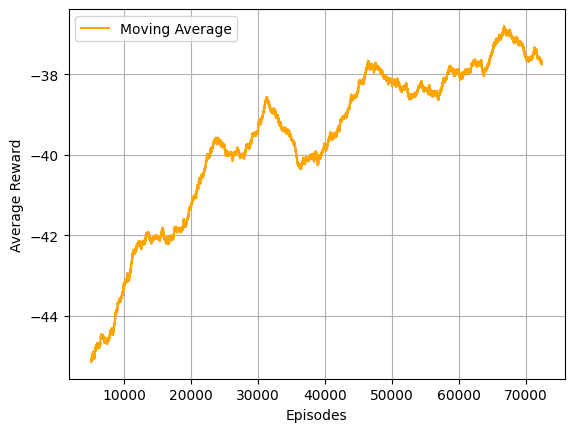

In [10]:


monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_3.csv"
# MONITOR_2 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 5000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

fig, ax = plt.subplots()
ax.plot(moving_average, label='Moving Average', color='orange')
ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

In [6]:
print(len(moving_average))

67731


I changed the calculation of latency. In order to do so, I slightly changed the buffer, which becomes a stack to capture the waiting time. 
The model is trained overnight, with 660000 (5 hours) + 1500000 (13 hours) steps.
(One episode has 40 steps)

The entropy loss of the policy goes from -22.5 to -13.2 during this 14 hours. The entropy loss evaluates the difference between the old and the new policy. It should be close to 0 when the policy converges. However, it is far from there. 


In [9]:
num_recorded_reward = (660000+1500000)/500
num_episode = (660000+1500000)/40
print(num_recorded_reward)
print(num_episode)
print(len(monitor_data['r']))

4320.0
54000.0
72466
